# SEMS: a short scentree demo

We follow the workflow: **historical data → scenario fan → scenario
tree → Pyomo → HiGHS**. The application is the four 15-minute intervals starting
at 12:00, 12:15, 12:30 and 12:45 on **31 December 2025**.

Only photovoltaic generation (PV) is uncertain. Demand and prices are known.
All modelling code is in this notebook. This edition uses the supplied,
unmodified **scentree 0.0.10** source.

**Setup:** use Python 3.12 and run `python -m pip install -r requirements.txt`
from the extracted demo folder. Open this notebook from that folder. Restart
the kernel and run all cells in order when switching from an older edition.

In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyomo.environ as pyo

# Use the supplied scentree source.
sys.path.insert(0, str(Path("scentree/scentree-main").resolve()))

## 1. Load the PV history and the four intervals

The CSV files are extracts of `lab2_2025.xlsx`. Each historical row is one day,
with four PV observations at the same quarter-hours. We use the 90 days from
2 October to 30 December 2025. The target day's PV is held out from forecasting.

`PV` and `D` are already **kWh per interval**. `spot` is **€/kWh**.
The interval labels use fixed CET (UTC+1).

In [2]:
history = pd.read_csv("data/pv_history.csv", float_precision="round_trip")
target = pd.read_csv("data/target_intervals.csv", parse_dates=["datetime"],
                     float_precision="round_trip")
Y = history[["PV_1", "PV_2", "PV_3", "PV_4"]].to_numpy()
demand = target["D"].to_numpy()
price = target["spot"].to_numpy()

print("Historical data shape (days, periods):", Y.shape)
display(target[["datetime", "PV", "D", "spot"]])

Historical data shape (days, periods): (90, 4)


,datetime,PV,D,spot
0,2025-12-31 12:00:00,4.570923,0.808694,0.08330
1,2025-12-31 12:15:00,4.577273,1.306349,0.08200
2,2025-12-31 12:30:00,4.616798,0.511136,0.08200
3,2025-12-31 12:45:00,4.588496,1.921605,0.08489


## 2. Describe the stochastic data to scentree

`Dataset` identifies the variable, its observation stages and its bounds.
`DatasetsLoader` supplies the ordered matrix and the stage mappings used below.
Here there is **one random variable, PV, at each of stages 1–4**. Stage 0 will be
the root, before any PV observation.

In [3]:
from scentree.io.loader import Dataset, DatasetsLoader

loader = DatasetsLoader(datasets=[
    Dataset(name="PV", values=Y, stage_ids=[1, 2, 3, 4], bounds=(0., np.inf))
])
full_values = loader.get_full_values()
stage_ids = loader.get_sorted_stage_ids()
num_vars = loader.get_num_variables_per_stage()
stage_cols_map = loader.create_stage_columns_mapping()

print("Observation stages:", stage_ids)
print("Variables per stage:", num_vars)
print("Stage-to-column mapping:", stage_cols_map)

Observation stages: [1, 2, 3, 4]
Variables per stage: [1, 1, 1, 1]
Stage-to-column mapping: {1: [0], 2: [1], 3: [2], 4: [3]}


## 3. Generate a scenario fan

`StageManager` fits a forecasting model and samples its residuals to create
possible PV trajectories. `num_fans=1` gives one forecast origin and
`num_scenarios=80` gives 80 possible four-period futures. Setting
`build_in_sample_fans=False` forecasts the day after the training data.

We retain the case study's **VAR-only forecasting choice** to compare the same
forecasting method across package versions. In scentree 0.0.10, PCA runs only
when the input has at least 10 columns by default. These data have four columns,
so the package fits VAR to the standardized PV values directly. No PCA threshold
override is needed. The estimator assignment below configures this notebook
session and does not edit the package source. The fan seed is **684**.

Without this explicit VAR selection, the package compares Ridge, SVR and VAR
and selects SVR for these data in the tested environment. That produces a
different fan and topology. The topology here is a teaching example, not a
forecast-quality selection criterion. Held-out target PV is never used in fitting
or selecting the tree settings.

In [4]:
from scentree.fan_generator import StageManager
from scentree.estimators.estimator_orchestrator import EstimatorController
from scentree.estimators.var import VarEstimator

# Retain the case study's forecasting method. Use the new PCA defaults.
EstimatorController.estimator_classes = [VarEstimator]

scenario_fans = StageManager().generate_scenario_fans(
    X=full_values,
    num_fans=1,
    num_scenarios=80,
    build_in_sample_fans=False,
    value_ranges=loader.get_full_bounds(),
    seed=684,
)
fan = scenario_fans["scenarios"][0]
print("Fan shape (scenarios, periods):", fan.shape)

c:\Users\fjavi\Documents\ChatGPT\REINFORCE SEMS\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Evaluating estimators: 100%|██████████| 1/1 [00:00<00:00, 28.73it/s, estimator=VarEstimator]

Fan shape (scenarios, periods): (80, 4)


## 4. Build a scenario tree with FTC

`FTC` groups the fan trajectories into a tree. `initial_stage_id_to_cluster=1`
starts clustering at the first PV observation. `r` is the exponent of the
distance criterion, **not a prescribed branching pattern**. We retain
**r = 30** and **seed = 15**. With the new package and the VAR configuration
above, these settings reproduce **1–3–11–11–17 nodes at stages 0–4**.

The result offers two views: `nac_formulation` contains reduced trajectory
matrices, while `nodal_formulation` contains the dictionaries needed by Pyomo.
We take those dictionaries directly, without rebuilding the tree.

In [5]:
from scentree.tree_construction.ftc import FTC

tree_structure = FTC(
    scenarios=scenario_fans["scenarios"],
    num_variables_per_stage=num_vars,
    stage_ids=stage_ids,
).generate_scenario_trees(
    stage_columns_mapping=stage_cols_map,
    initial_stage_id_to_cluster=1,
    r=30.,
    seed=15,
)
tree_data = tree_structure["nac_formulation"][0]["scenario_tree_data"]
nodal = tree_structure["nodal_formulation"][0]
parent = nodal["parent"]
stage = nodal["stage"]
xi = nodal["random_variable_value"]
pi = nodal["probability"]

print("Nodes at stages 0–4:", [sum(stage[n] == s for n in stage) for s in range(5)])
display(pd.DataFrame({"parent": parent, "stage": stage, "xi (PV)": xi, "pi": pi}).head(8))

Building trees: 100%|██████████| 1/1 [00:00<00:00, 31.40it/s]

Nodes at stages 0–4: [1, 3, 11, 11, 17]


,parent,stage,xi (PV),pi
0,NaN,0,None,1.0000
1,0.0,1,[4.058072121321644],0.6250
2,0.0,1,[4.3172718338963065],0.3625
3,0.0,1,[4.090476332471527],0.0125
4,3.0,2,[4.214450790488119],0.0125
5,1.0,2,[4.045270792785396],0.0875
6,1.0,2,[3.7365571708761895],0.4500
7,1.0,2,[3.851117022238694],0.0125


## 5. Compare the history, fan and reduced trajectories

The dashed line shows the held-out target PV for visual comparison only.
The reduced matrix keeps one row per original fan scenario, so several rows
can follow the same reduced path. The nodal dictionaries describe the actual
branching structure and its probabilities.

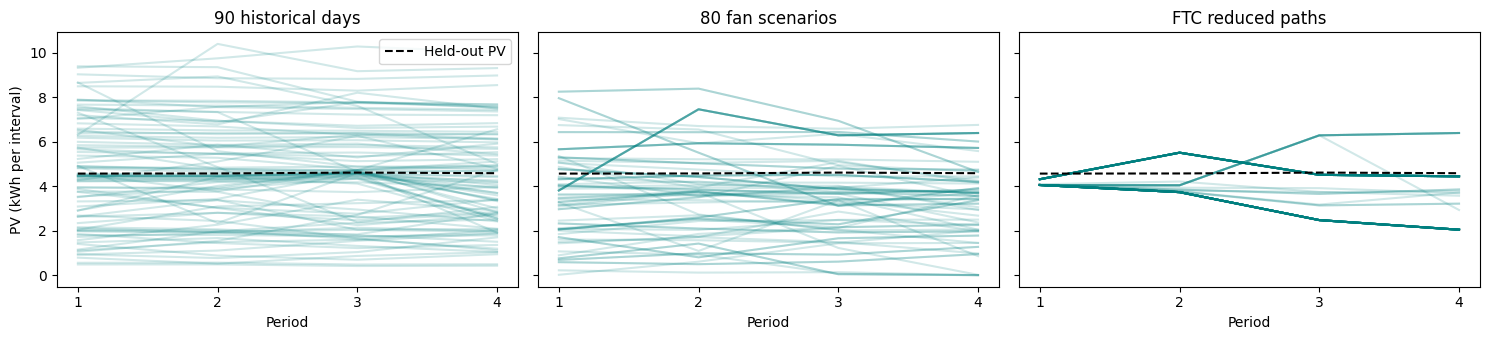

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for ax, values, title in zip(axes, [Y, fan, tree_data],
                            ["90 historical days", "80 fan scenarios", "FTC reduced paths"]):
    ax.plot(range(1, 5), values.T, color="teal", alpha=0.18)
    ax.plot(range(1, 5), target["PV"], "k--", label="Held-out PV")
    ax.set(title=title, xlabel="Period", xticks=range(1, 5))
axes[0].set_ylabel("PV (kWh per interval)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 6. Use the raw dictionaries in the SEMS model

| scentree dictionary | SEMS meaning |
|---|---|
| `parent[n]` | $p(n)$, predecessor of node $n$. It is `None` at the root. |
| `stage[n]` | $s(n)$, number of PV observations so far, from 0 to 4. |
| `xi[n]` | PV observed at node $n$. Its one-element array is read with `.item()`. |
| `pi[n]` | $pi_n$, unconditional probability of reaching node $n$. |

A node at stage $s<4$ decides the operation for period $s+1$, before that
period's PV is known. Its child observes that PV and settles the imbalance.
Thus, for each node with a parent $p=p(n)$,

$$SOC_n=SOC_p+(charge_p-discharge_p)/60,$$
$$imb^+_n-imb^-_n=PV_n+discharge_p+buy_p-charge_p-sell_p-D_{s(n)}.$$

The lossless battery has capacity **60 kWh**, initial SOC **50%**, SOC bounds
**30–80%**, and a charge/discharge limit of **7.5 kWh per interval**. Scheduled
grid exchanges are limited to **25 kWh per interval**. Buying costs `spot + 0.12`
and selling earns `spot`. The assumed imbalance penalty is **€0.30/kWh** in
either direction. There is no terminal SOC target or degradation cost, so the
profit includes use of the initial battery inventory.

The code indexes variables directly from `stage` and `parent`. Bootstrap ties
can create distinct nodes with identical PV histories. The short final loop
gives such nodes the same action, so the policy cannot use their labels as
extra information.

In [7]:
root = next(n for n in parent if parent[n] is None)
model = pyo.ConcreteModel()
model.charge = pyo.Var([n for n in stage if stage[n] < 4], bounds=(0, 7.5))
model.discharge = pyo.Var([n for n in stage if stage[n] < 4], bounds=(0, 7.5))
model.buy = pyo.Var([n for n in stage if stage[n] < 4], domain=pyo.NonNegativeReals)
model.sell = pyo.Var([n for n in stage if stage[n] < 4], domain=pyo.NonNegativeReals)
model.soc = pyo.Var(stage, bounds=(0.30, 0.80))
model.imb_plus = pyo.Var([n for n in parent if parent[n] is not None],
                         domain=pyo.NonNegativeReals)
model.imb_minus = pyo.Var([n for n in parent if parent[n] is not None],
                          domain=pyo.NonNegativeReals)
model.soc[root].fix(0.50)
model.constraints = pyo.ConstraintList()

for n in stage:
    if stage[n] < 4:
        model.constraints.add(model.buy[n] + model.sell[n] <= 25)
    if parent[n] is not None:
        p = parent[n]
        model.constraints.add(model.soc[n] == model.soc[p]
                              + (model.charge[p] - model.discharge[p]) / 60)
        model.constraints.add(model.imb_plus[n] - model.imb_minus[n]
                              == xi[n].item() + model.discharge[p] + model.buy[p]
                              - model.charge[p] - model.sell[p] - demand[stage[n] - 1])

# Nodes with the same observed PV history must take the same action.
observations, first_node = {root: ()}, {}
for n in sorted(stage, key=stage.get):
    if parent[n] is not None:
        observations[n] = observations[parent[n]] + (xi[n].item(),)
    if stage[n] < 4:
        if observations[n] in first_node:
            previous = first_node[observations[n]]
            for flow in [model.charge, model.discharge, model.buy, model.sell]:
                model.constraints.add(flow[n] == flow[previous])
        first_node[observations[n]] = n

model.profit = pyo.Objective(sense=pyo.maximize, expr=
    sum(pi[n] * (price[stage[n]] * model.sell[n]
                 - (price[stage[n]] + 0.12) * model.buy[n])
        for n in stage if stage[n] < 4)
    - 0.30 * sum(pi[n] * (model.imb_plus[n] + model.imb_minus[n])
                 for n in parent if parent[n] is not None))

## 7. Solve with HiGHS and inspect the policy

The objective is expected sales revenue minus purchasing costs and imbalance
penalties. The initial action is common to all scenarios. Later actions depend
on observed PV. A stage-4 node has only final SOC and settlement.

This demo uses one profit-maximization solve. Several policies can share the same optimal profit.

In [8]:
solver = pyo.SolverFactory("appsi_highs")
solution = solver.solve(model)
pyo.assert_optimal_termination(solution)

print(f"Expected profit: €{pyo.value(model.profit):.6f}")
print("Initial action (kWh):", {
    name: round(pyo.value(getattr(model, name)[root]), 4)
    for name in ["sell", "buy", "charge", "discharge"]
})

policy = pd.DataFrame([
    {"node": n, "parent": parent[n], "stage": stage[n], "pi": pi[n],
     "PV": xi[n].item() if parent[n] is not None else np.nan,
     "SOC (%)": 100 * pyo.value(model.soc[n]),
     **{name: pyo.value(getattr(model, name)[n]) if stage[n] < 4 else np.nan
        for name in ["sell", "buy", "charge", "discharge"]},
     "imbalance": pyo.value(model.imb_plus[n] - model.imb_minus[n])
                  if parent[n] is not None else 0.}
    for n in stage
])
display(policy.round(4))

Expected profit: €1.875292
Initial action (kWh): {'sell': 11.0086, 'buy': 0.0, 'charge': 0.0, 'discharge': 7.5}


,node,parent,stage,pi,PV,SOC (%),sell,buy,charge,discharge,imbalance
0,0,NaN,0,1.0000,NaN,50.0000,11.0086,0.0,0.0000,7.5000,0.0000
1,1,0.0,1,0.6250,4.0581,37.5000,1.3975,0.0,1.0327,0.0000,-0.2592
2,2,0.0,1,0.3625,4.3173,37.5000,5.2119,0.0,0.0000,1.0053,0.0000
3,3,0.0,1,0.0125,4.0905,37.5000,3.1433,0.0,0.0000,0.2352,-0.2268
4,4,3.0,2,0.0125,4.2145,37.1081,0.0000,0.0,3.2352,0.0000,0.0000
5,5,1.0,2,0.0875,4.0453,39.2212,3.8145,0.0,1.9673,0.0000,0.3087
6,6,1.0,2,0.4500,3.7366,39.2212,0.0000,0.0,1.9673,0.0000,0.0000
7,7,1.0,2,0.0125,3.8511,39.2212,1.1777,-0.0,1.9673,-0.0000,0.1146
8,8,1.0,2,0.0125,3.7640,39.2212,0.6603,-0.0,1.9673,-0.0000,0.0275
9,9,1.0,2,0.0125,3.8216,39.2212,1.2580,0.0,1.9673,0.0000,0.0851


## 8. Optional: show the policy on the tree

The same `parent` and `stage` dictionaries define the edges and columns.
We reserve one row for each terminal node so labels do not overlap.
`S/B` denotes sale/purchase and `C/D` charge/discharge, all in kWh.

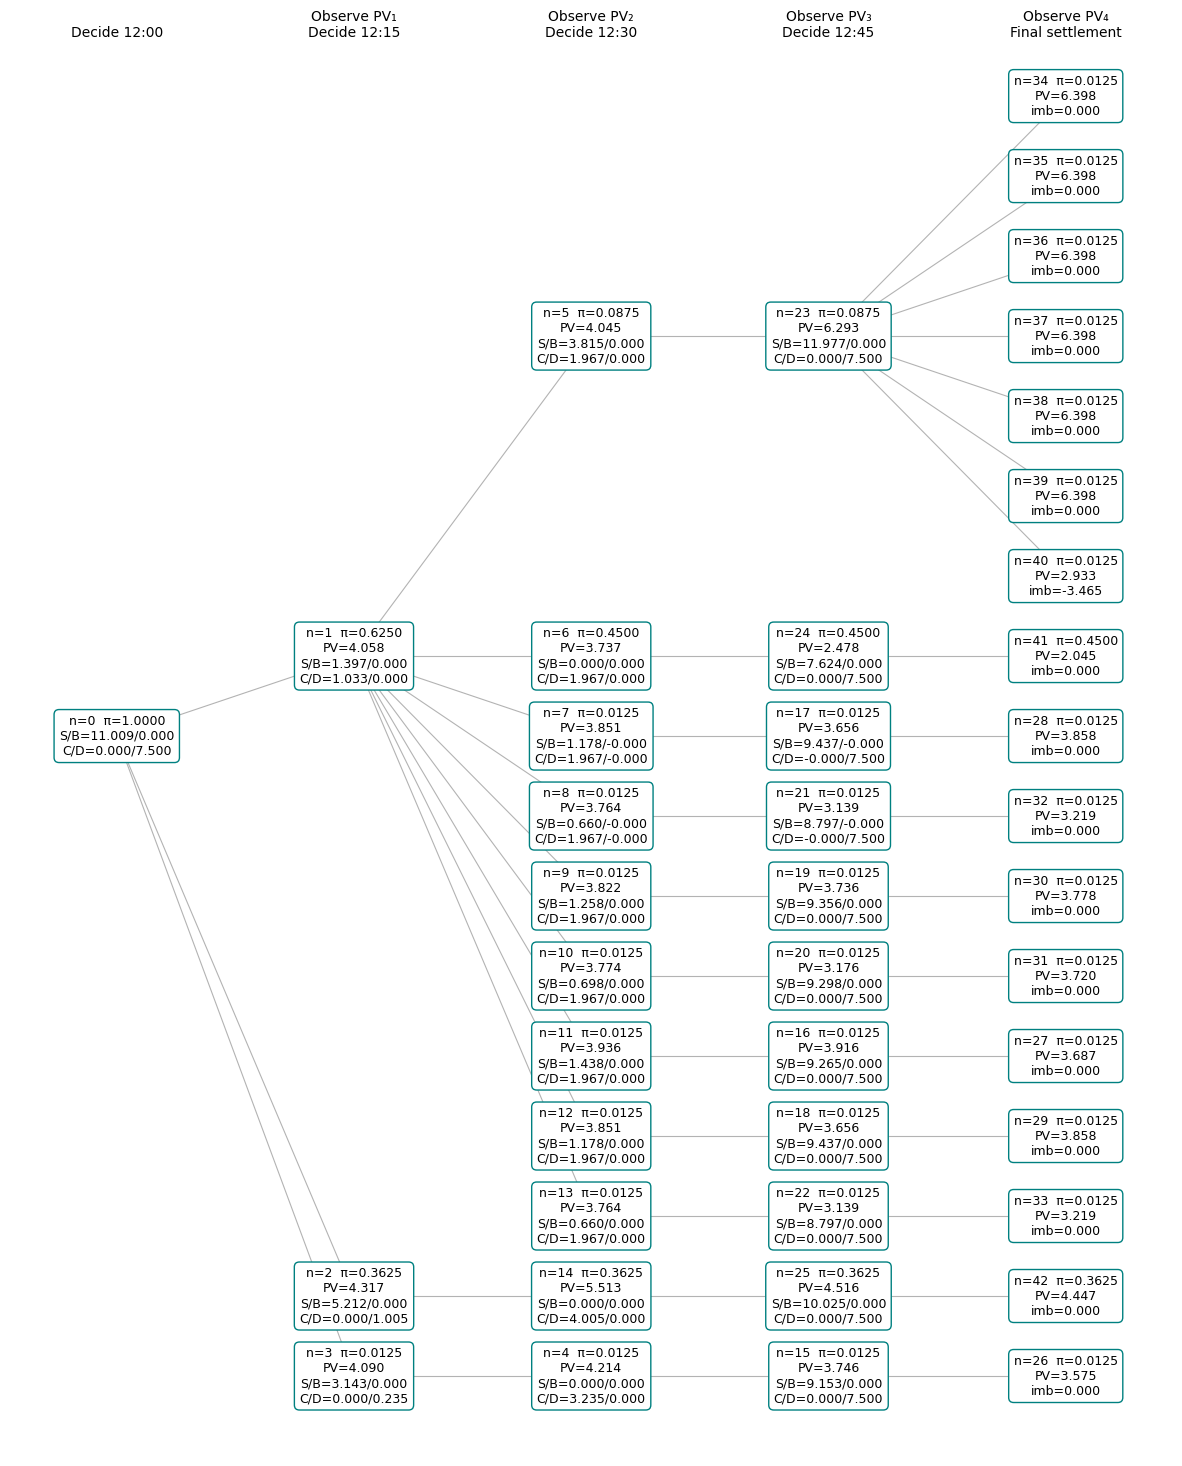

In [9]:
children = {n: [c for c in parent if parent[c] == n] for n in stage}
def terminal_nodes(n):
    return [n] if not children[n] else [leaf for c in children[n] for leaf in terminal_nodes(c)]

leaves = terminal_nodes(root)
leaf_y = {n: i for i, n in enumerate(leaves)}
y = {n: np.mean([leaf_y[leaf] for leaf in terminal_nodes(n)]) for n in stage}
fig, ax = plt.subplots(figsize=(15, max(6, len(leaves) * 1.1)))
for n in parent:
    if parent[n] is not None:
        ax.plot([stage[parent[n]], stage[n]], [y[parent[n]], y[n]],
                color="0.7", linewidth=0.8, zorder=0)
for row in policy.to_dict("records"):
    n = row["node"]
    label = f"n={n}  π={pi[n]:.4f}"
    if parent[n] is not None:
        label += f"\nPV={row['PV']:.3f}"
    if stage[n] < 4:
        label += f"\nS/B={row['sell']:.3f}/{row['buy']:.3f}"
        label += f"\nC/D={row['charge']:.3f}/{row['discharge']:.3f}"
    else:
        label += f"\nimb={row['imbalance']:.3f}"
    ax.text(stage[n], y[n], label, ha="center", va="center", fontsize=9,
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="teal"))
ax.set(xlim=(-0.45, 4.45), ylim=(len(leaves), -1))
ax.axis("off")
for s, label in enumerate(["Decide 12:00", "Observe PV₁\nDecide 12:15",
                           "Observe PV₂\nDecide 12:30", "Observe PV₃\nDecide 12:45",
                           "Observe PV₄\nFinal settlement"]):
    ax.text(s, -0.7, label, ha="center", va="bottom", fontsize=10)
plt.show()